https://colab.research.google.com/drive/1zafx9Izsnhv2-PpJ4PP8Y2gOALbLx7_B?usp=sharing

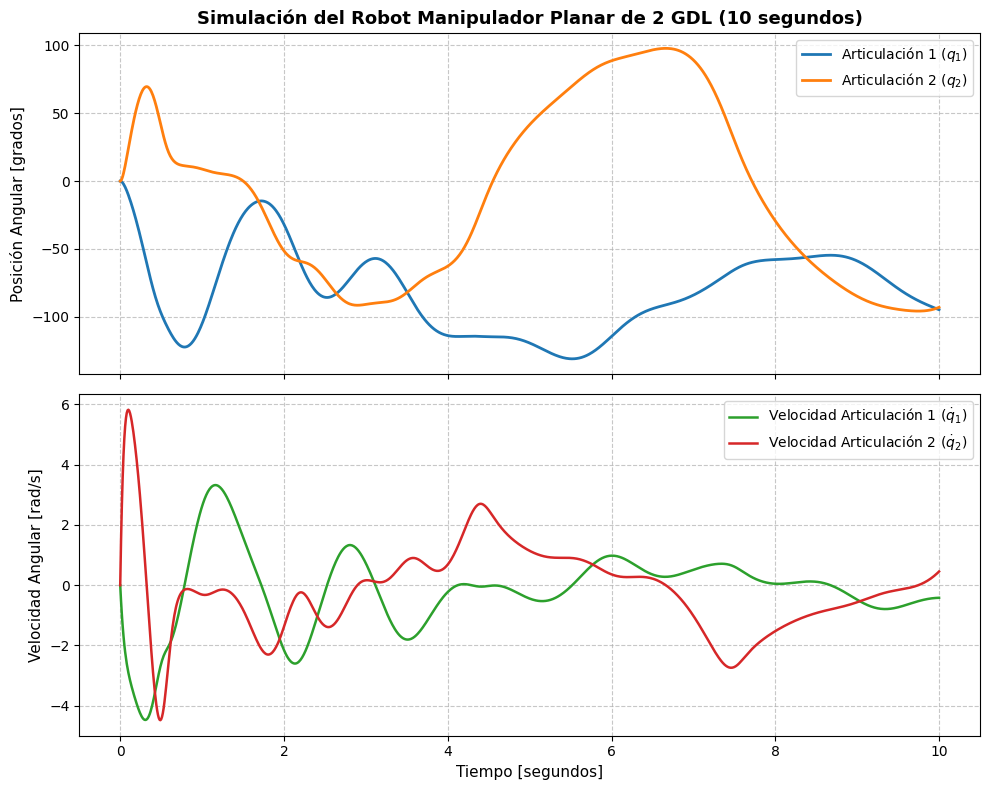

In [1]:
import numpy as np
from scipy.integrate import solve_ivp
import matplotlib.pyplot as plt

# ==============================================================================
# 1. PARÁMETROS DEL ROBOT (Basados en Tabla 5.1 - Ejemplo 5.3 de F. Reyes Cortés)
# ==============================================================================
m1 = 1.5       # Masa del eslabón 1 [kg]
m2 = 1.0       # Masa del eslabón 2 [kg]
l1 = 0.5       # Longitud del eslabón 1 [m]
l2 = 0.4       # Longitud del eslabón 2 [m]
lc1 = 0.25     # Distancia al centro de masa del eslabón 1 [m]
lc2 = 0.20     # Distancia al centro de masa del eslabón 2 [m]
I1 = 0.0312    # Momento de inercia del eslabón 1 [kg*m^2]
I2 = 0.0133    # Momento de inercia del eslabón 2 [kg*m^2]
g_acc = 9.81   # Aceleración de la gravedad [m/s^2]

# Coeficientes de fricción viscosa en las articulaciones
b1 = 0.5       # Fricción viscosa articulación 1 [N*m*s/rad]
b2 = 0.3       # Fricción viscosa articulación 2 [N*m*s/rad]

# ==============================================================================
# 2. DEFINICIÓN DE LAS MATRICES DEL MODELO DINÁMICO (Euler-Lagrange)
#    Ecuación: M(q)*q_ddot + C(q, q_dot)*q_dot + g(q) + f(q_dot) = tau
# ==============================================================================

def matriz_inercia(q):
    """Calcula la matriz de inercia M(q) de 2x2."""
    q1, q2 = q
    c2 = np.cos(q2)

    M11 = m1 * lc1**2 + m2 * (l1**2 + lc2**2 + 2 * l1 * lc2 * c2) + I1 + I2
    M12 = m2 * (lc2**2 + l1 * lc2 * c2) + I2
    M21 = M12
    M22 = m2 * lc2**2 + I2

    return np.array([[M11, M12],
                     [M21, M22]])

def matriz_coriolis(q, q_dot):
    """Calcula la matriz de fuerzas centrífugas y de Coriolis C(q, q_dot) de 2x2."""
    q1, q2 = q
    dq1, dq2 = q_dot
    h = -m2 * l1 * lc2 * np.sin(q2)

    C11 = h * dq2
    C12 = h * (dq1 + dq2)
    C21 = -h * dq1
    C22 = 0.0

    return np.array([[C11, C12],
                     [C21, C22]])

def vector_gravedad(q):
    """Calcula el vector de pares gravitacionales g(q) de 2x1."""
    q1, q2 = q
    g1 = (m1 * lc1 + m2 * l1) * g_acc * np.cos(q1) + m2 * lc2 * g_acc * np.cos(q1 + q2)
    g2 = m2 * lc2 * g_acc * np.cos(q1 + q2)

    return np.array([g1, g2])

def vector_friccion(q_dot):
    """Calcula el vector de fricción viscosa f(q_dot) de 2x1."""
    dq1, dq2 = q_dot
    f1 = b1 * dq1
    f2 = b2 * dq2
    return np.array([f1, f2])

def pares_motores(t):
    """
    Define los pares (torques) aplicados por los motores en cada articulación [N*m].
    """
    tau1 = 5.0 * np.sin(t)   # Torque dinámico en motor 1
    tau2 = 2.0 * np.cos(t)   # Torque dinámico en motor 2
    return np.array([tau1, tau2])

# ==============================================================================
# 3. ECUACIÓN DIFERENCIAL DEL SISTEMA (Espacio de Estados)
# ==============================================================================

def dinamica_robot(t, estado):
    """
    estado = [q1, q2, dq1, dq2]
    Despejamos aceleración: q_ddot = M(q)^(-1) * [tau - C(q, q_dot)*q_dot - g(q) - f(q_dot)]
    """
    q = estado[0:2]
    q_dot = estado[2:4]

    M = matriz_inercia(q)
    C = matriz_coriolis(q, q_dot)
    g = vector_gravedad(q)
    f = vector_friccion(q_dot)
    tau = pares_motores(t)

    rhs = tau - (C @ q_dot) - g - f
    q_ddot = np.linalg.solve(M, rhs)

    return np.concatenate((q_dot, q_ddot))

# ==============================================================================
# 4. SIMULACIÓN NUMÉRICA (0 a 10 segundos)
# ==============================================================================

t_span = (0, 10)                          # Tiempo total de 10 segundos
t_eval = np.linspace(0, 10, 1000)         # 1000 puntos de evaluación
estado_inicial = [0.0, 0.0, 0.0, 0.0]     # [q1(0), q2(0), dq1(0), dq2(0)] en radianes

solucion = solve_ivp(dinamica_robot, t_span, estado_inicial, t_eval=t_eval, method='RK45')

t = solucion.t
q1_rad = solucion.y[0]
q2_rad = solucion.y[1]
dq1_rad = solucion.y[2]
dq2_rad = solucion.y[3]

q1_deg = np.rad2deg(q1_rad)
q2_deg = np.rad2deg(q2_rad)

# ==============================================================================
# 5. VISUALIZACIÓN DE RESULTADOS
# ==============================================================================

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 8), sharex=True)

# Gráfica 1: Posición articular en grados
ax1.plot(t, q1_deg, label=r'Articulación 1 ($q_1$)', color='#1f77b4', linewidth=2)
ax1.plot(t, q2_deg, label=r'Articulación 2 ($q_2$)', color='#ff7f0e', linewidth=2)
ax1.set_title('Simulación del Robot Manipulador Planar de 2 GDL (10 segundos)', fontsize=13, fontweight='bold')
ax1.set_ylabel('Posición Angular [grados]', fontsize=11)
ax1.grid(True, linestyle='--', alpha=0.7)
ax1.legend(loc='upper right', fontsize=10)

# Gráfica 2: Velocidad articular
ax2.plot(t, dq1_rad, label=r'Velocidad Articulación 1 ($\dot{q}_1$)', color='#2ca02c', linewidth=1.8)
ax2.plot(t, dq2_rad, label=r'Velocidad Articulación 2 ($\dot{q}_2$)', color='#d62728', linewidth=1.8)
ax2.set_xlabel('Tiempo [segundos]', fontsize=11)
ax2.set_ylabel('Velocidad Angular [rad/s]', fontsize=11)
ax2.grid(True, linestyle='--', alpha=0.7)
ax2.legend(loc='upper right', fontsize=10)

plt.tight_layout()
plt.show()
